# Notebook 02: Modelling

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))     # agar paket `scripts` bisa di-import (notebook dijalankan dari notebooks/)

import warnings
warnings.filterwarnings('ignore')
import time, json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, classification_report

from scripts.config import DATA_DIR, MODEL_DIR, SUBMISSION_DIR, FIGURE_DIR, CATS, GEO, SEED_SPLIT
DATA_DIR = str(DATA_DIR)     # folder train.csv & test.csv (data/)
for d in (MODEL_DIR, SUBMISSION_DIR, FIGURE_DIR): d.mkdir(parents=True, exist_ok=True)
cats, geo = CATS, GEO        # kolom kategorik bangunan & kolom ID wilayah

1. Load data & label

In [2]:
from scripts.preprocess import load_data

tr, te = load_data(DATA_DIR)    # tr punya kolom y (0..4) dari 'Grade 3' -> 2 (syarat LightGBM); te tanpa target
allids = pd.concat([tr.building_id, te.building_id], ignore_index=True)  # semua ID (train+test), dipakai hitung jumlah bangunan per kelompok (tanpa label)
print(tr.shape, te.shape)

(533465, 18) (228629, 16)


2. Fitur dasar

Fitur bawaan + fitur turunan: rasio bangunan, dan kelompok lokasi yang diambil dari potongan digit building_id.

In [3]:
from scripts.preprocess import BaseFeatureBuilder      # transformer sklearn: umur di-clip 200, rasio luas/tinggi per lantai, kelompok lokasi dari ID

BaseFeatureBuilder(all_ids=allids).transform(tr.head(1000)).head()   # contoh keluaran fitur dasar

,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,...,plan_configuration,superstructure,area_per_floor,height_per_floor,id_loc,id_seq,n_g8,n_g6,n_g4,n_g3
0,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,...,Rectangular,has_superstructure_mud_mortar_stone,168.0,7.0,280803013,271,6930,850,364,70
1,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,...,Rectangular,has_superstructure_cement_mortar_brick,190.0,8.0,311908002,31,2983,375,375,102
2,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,...,Rectangular,has_superstructure_mud_mortar_stone,187.5,8.0,310303000,362,1797,115,41,41
3,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,...,Rectangular,has_superstructure_adobe_mud,159.5,7.5,280806040,201,6930,481,135,109
4,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,...,Rectangular,has_superstructure_mud_mortar_stone,495.0,6.0,291301000,371,983,96,96,96


3. Fitur lokasi (Target Encoding)


Untuk tiap kelompok lokasi, hitung proporsi tiap kelas kerusakan (grade 1–5) dari data referensi. Dipakai smoothing supaya kelompok kecil tidak ekstrem:
(jumlah + 5·prior) / (n + 5)

In [4]:
from scripts.feature_engineering import keys, te_features   # kunci kelompok lokasi & proporsi kelas per kelompok (smoothing a=5)

te_features(tr.head(500), tr.iloc[500:5000]).keys().__len__()    # 7 kelompok x 5 kelas = 35 fitur

35

4. Fitur tetangga

Urutkan semua ID di data referensi. Untuk tiap bangunan, lihat bangunan-bangunan di kiri/kanan posisinya pada urutan itu.
- Tetangga umum: rata-rata kerusakan di jendela k = 3, 10, 30, 100 (multi-skala), label tetangga langsung, jarak ID, dan kepadatan.
- Tetangga bersyarat: hanya tetangga dengan atribut yang sama (superstruktur, fondasi, jumlah lantai, lantai dasar) → membandingkan "apel dengan apel".

In [5]:
from scripts.feature_engineering import nb_features, cond_nb_features, feats   # tetangga umum, tetangga bersyarat, dan gabungannya

print(feats(tr.head(500), tr.iloc[500:5000]).shape)    # contoh: fitur lokasi/tetangga untuk 500 baris

(500, 94)


5. Out-of-fold (anti kebocoran label)
Jika fitur sebuah baris dihitung dari labelnya sendiri, model akan "menyontek" dan skor validasi menjadi palsu. Solusinya: data dibagi 10 fold; fitur tiap fold dihitung hanya dari 9 fold lainnya. Untuk data test, referensinya seluruh train.

Pipeline & ColumnTransformer: Skema out-of-fold dibungkus di LocationFeatureBuilder (fit_transform = out-of-fold untuk data latih, transform = referensi seluruh train untuk validasi/test). Semua tahap dirangkai dalam satu Pipeline:

| Langkah | Isi |
|---|---|
| `features` | `ColumnTransformer`: `BaseFeatureBuilder` + `LocationFeatureBuilder` |
| `encode` | `ColumnTransformer`: `CategoryEncoder` (tipe `category` untuk kolom kategorik + wilayah) |
| `model` | `LGBMBoosterClassifier` (pembungkus `lightgbm.train`) |

In [6]:
from scripts.feature_engineering import oof
from scripts.train import build_pipeline

build_pipeline(allids)    # tampilkan struktur pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('encode', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('base', ...), ('location', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feat

6. Parameter model

In [7]:
from scripts.config import LGB_PARAMS as p
p

{'objective': 'multiclass',
 'num_class': 5,
 'learning_rate': 0.06,
 'num_leaves': 63,
 'min_data_in_leaf': 60,
 'feature_fraction': 0.5,
 'bagging_fraction': 0.8,
 'bagging_freq': 1,
 'lambda_l2': 5,
 'cat_smooth': 20,
 'max_cat_to_onehot': 8,
 'verbose': -1,
 'num_threads': 1,
 'max_bin': 63}

7. Tahap 1: Validasi (mengukur performa dengan jujur)

Sisihkan 20% train sebagai validasi. Fitur train dihitung out-of-fold; fitur validasi dihitung dari train saja (meniru kondisi test).

In [8]:
t = time.time()                                                                    # catat waktu mulai
A, B = train_test_split(tr, test_size=0.2, stratify=tr.y, random_state=SEED_SPLIT) # A = 80% latih, B = 20% validasi (stratify = proporsi kelas dijaga)
A = A.reset_index(drop=True)
B = B.reset_index(drop=True)

from scripts.train import build_pipeline
pipe = build_pipeline(allids)
prep = pipe[:-1]                                                                   # semua langkah sebelum model (features + encode)
XA = prep.fit_transform(A.drop(columns=['damage_grade', 'y']), A.y.values)         # fitur latih (out-of-fold)
XB = prep.transform(B.drop(columns=['damage_grade', 'y']))                         # fitur validasi (referensi = A saja, kategori disamakan dgn XA)
print('features built', time.time() - t, XA.shape)

features built 22.446683406829834 (426772, 117)


In [11]:
import lightgbm 

model = pipe.named_steps['model']
model.fit(XA, A.y.values, eval_set=(XB, B.y.values))      # maks 1500 iterasi, early stopping 40, log tiap 50
bi = model.best_iteration_                                 # jumlah iterasi terbaik
print('train time', time.time() - t, 'best', bi)
pv = model.predict_proba(XB)                               # probabilitas 5 kelas untuk data validasi
yv = B.y.values                                            # label sebenarnya data validasi
print('val macroF1 raw', f1_score(yv, pv.argmax(1), average='macro'),
      'acc', (pv.argmax(1) == yv).mean())

Training until validation scores don't improve for 40 rounds
[50]	valid_0's multi_logloss: 0.913859
[100]	valid_0's multi_logloss: 0.897259
[150]	valid_0's multi_logloss: 0.893791
[200]	valid_0's multi_logloss: 0.892702
[250]	valid_0's multi_logloss: 0.892028
[300]	valid_0's multi_logloss: 0.89195
[350]	valid_0's multi_logloss: 0.891934
Early stopping, best iteration is:
[328]	valid_0's multi_logloss: 0.89187
train time 454.951700925827 best 328
val macroF1 raw 0.5914207219621626 acc 0.6257017798730938


Penyetelan bobot kelas untuk Macro F1

argmax probabilitas mengoptimalkan akurasi, sedangkan Macro F1 menganggap tiap kelas sama penting. Probabilitas tiap kelas dikalikan bobot, dicari lewat *coordinate ascent* di data validasi.

In [12]:
from scripts.train import tune_class_weights, macro_f1_with_weights

w, best = tune_class_weights(pv, yv)       # coordinate ascent, 3 putaran, bobot 0.5-2.5
print('val macroF1 tuned', best, w)        # skor akhir & bobot terbaik
json.dump({'w': w.tolist(), 'iters': int(bi), 'f1': best}, open(MODEL_DIR / 'cfg3.json', 'w'))  # simpan hasil tuning
imp = model.feature_importance()           # fitur paling berpengaruh (berdasar gain)
imp.head(15)                               # tampilkan 15 teratas -> bukti fitur lokasi/tetangga penting

val macroF1 tuned 0.5958523640823741 [0.8 1.2 1.2 1.1 0.8]


ward_id         622129.646664
c_groun_5_4     317311.850706
c_super_5_0     240104.959307
c_super_20_3    224865.602381
c_super_5_4     204869.414083
te_g6sup_0      190080.731319
c_super_20_0    178548.386092
c_super_20_4    160694.693537
c_groun_20_4    148198.451020
c_found_5_4     145968.535691
c_super_20_2    137432.328571
te_g6sup_2      130150.231128
te_g6sup_1      121464.297719
age_building    117154.941252
c_super_20_1    110859.955270
dtype: float64

Menyimpan *feature importance* dan *confusion matrix* validasi ke reports/figures/ (dipakai di README).

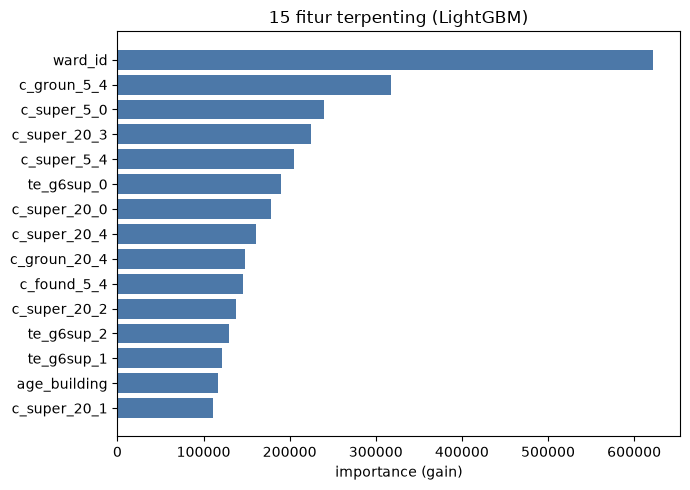

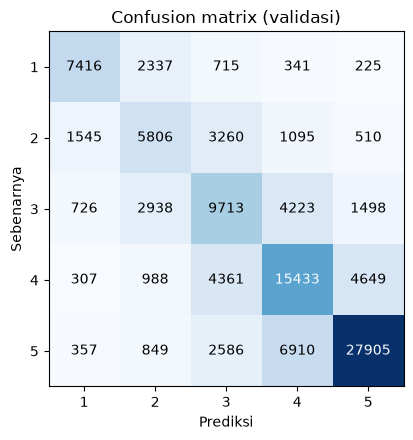

              precision    recall  f1-score   support

           1      0.716     0.672     0.694     11034
           2      0.449     0.475     0.462     12216
           3      0.471     0.509     0.489     19098
           4      0.551     0.600     0.574     25738
           5      0.802     0.723     0.760     38607

    accuracy                          0.621    106693
   macro avg      0.598     0.596     0.596    106693
weighted avg      0.633     0.621     0.626    106693



In [13]:
top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color='#4C78A8')
ax.set_xlabel('importance (gain)'); ax.set_title('15 fitur terpenting (LightGBM)')
plt.tight_layout(); plt.savefig(FIGURE_DIR / 'feature_importance.png', dpi=130); plt.show()

pred_val = (pv * w).argmax(1)                         # prediksi validasi dengan bobot kelas hasil tuning
cm = confusion_matrix(yv, pred_val)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap='Blues'); ax.set_xticks(range(5)); ax.set_yticks(range(5))
ax.set_xticklabels(range(1, 6)); ax.set_yticklabels(range(1, 6))
ax.set_xlabel('Prediksi'); ax.set_ylabel('Sebenarnya'); ax.set_title('Confusion matrix (validasi)')
for i in range(5):
    for j in range(5):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout(); plt.savefig(FIGURE_DIR / 'confusion_matrix.png', dpi=130); plt.show()
print(classification_report(yv + 1, pred_val + 1, digits=3))

8. Tahap 2: Model akhir & submission

Latih ulang di seluruh train (lebih banyak data), dengan jumlah iterasi = 1,1 × iterasi terbaik. Prediksi test, lalu kalikan bobot kelas.

Pada notebook ini model akhir dilatih dan disimpan (models/pipeline_model_lgbm.pkl). Prediksi test dan pembuatan submission.csv ada di 03_submission.ipynb.

In [14]:
from scripts.train import train_final, save_artifacts

t = time.time()                                                  # catat waktu mulai
Tr = tr.reset_index(drop=True)                                   # seluruh train dengan index rapi
final = train_final(Tr, allids, bi)                              # Pipeline.fit di seluruh train; iterasi = 1,1 x terbaik
save_artifacts(final, w, bi, best)                               # simpan pipeline -> models/pipeline_model_lgbm.pkl & models/cfg3.json
print('model akhir tersimpan di', MODEL_DIR, '| waktu', time.time() - t)

final done 342.4269959926605
model akhir tersimpan di C:\Users\HP\Downloads\structural-damage-classification (1)\structural-damage-classification\models | waktu 344.8382074832916
